# STUDENT LAB WORKSHEET: End-to-End regresní pipeline a zpracování reálných dat

**Odhadovaná délka cvičení:** 80 minut  
**Potřebné nástroje:** Počítač s webovým prohlížečem, Google účet, přístup k prostředí Google Colab.

## 1. Co se naučíte
Po úspěšném dokončení tohoto cvičení budete schopni:
1. **Identifikovat a zabránit** metodické chybě zvané únik informací (data leakage) správným umístěním funkce pro rozdělení dat.
2. **Sestavit** objekt `ColumnTransformer` pro oddělené a bezpečné předzpracování numerických a kategoriálních příznaků.
3. **Použít** metody `SimpleImputer` a `OneHotEncoder` k algoritmickému ošetření neúplných a textových dat.
4. **Integrovat** kroky předzpracování a samotný model do jediné struktury pomocí třídy `Pipeline`.
5. **Vyhodnotit** přesnost modelu pomocí metriky RMSE a kriticky ji porovnat s teoretickou hranicí šumu v datech.

## 2. Kontext a motivace
Představte si, že pracujete jako datoví analytici a dostali jste za úkol vytvořit model pro predikci platu zaměstnance. K dispozici máte data o délce praxe, věku, bonusech, oddělení a dosaženém vzdělání.

V reálném světě jsou data zřídkakdy čistá. Databáze často obsahují prázdná místa (nevyplněné položky v dotazníku) a textové popisky. Matematické modely, jako je lineární regrese, ale umí pracovat pouze s čísly. V tomto cvičení si ukážeme, jak taková heterogenní (smíšená) a neúplná data automatizovaně a metodicky správně připravit pro strojové učení tak, abyste minimalizovali zkreslení výsledků.

## 3. Klíčové pojmy
* **NaN (Not a Number):** Zástupná hodnota, která v Pythonu reprezentuje chybějící nebo neznámá data.
* **Imputace (Imputation):** Proces algoritmického nahrazení chybějících hodnot (např. průměrem, mediánem nebo nejčastější hodnotou).
* **One-Hot Encoding:** Metoda transformace textových kategorií (např. "HR", "IT") na sérii nových sloupců, které obsahují pouze binární hodnoty 0 a 1.
* **Data Leakage (Únik informací):** Závažná metodická chyba, kdy model získá v trénovací fázi informace z testovacích dat. Vede k falešně optimistickému hodnocení modelu.
* **RMSE (Root Mean Squared Error):** Metrika chybovosti modelu. Udává průměrnou chybu ve stejných jednotkách, jako má cílová proměnná.

---

## 4. Guided lab (Průzkum ukázky)

### Krok A: Analýza baseline modelu
* **Účel:** Pochopit, jak knihovna `scikit-learn` implementuje polynomiální regresi na jednoduchém 1D případu.
* **Instrukce:** Spusťte následující buňku s kódem.
* **Co pozorovat:** Model pro "polynomiální" regresi se trénuje pomocí třídy `LinearRegression()`. Trik spočívá v tom, že data jsou nejprve nelineárně transformována pomocí `PolynomialFeatures`.
* **ÚKOL:** Všimněte si, že do proměnné `mse` se ukládá výsledek `root_mean_squared_error`. Textový výpis (`print`) ale říká "Mean Squared Error". **Opravte text uvnitř funkce `print` tak, aby terminologicky odpovídal skutečně počítané metrice.**



Root Mean Squared Error (RMSE): 878.84


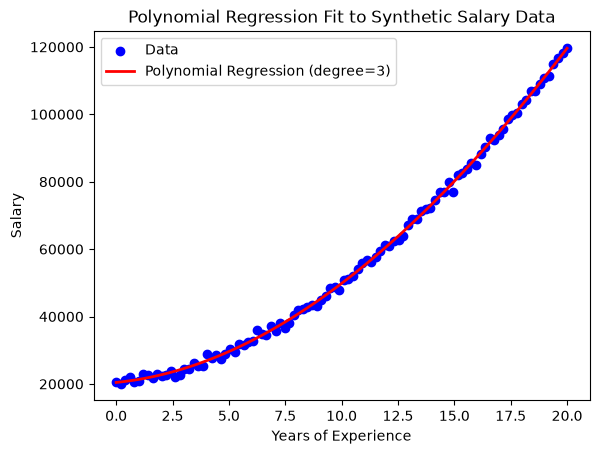

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import root_mean_squared_error

# Set random seed for reproducibility
np.random.seed(42)

# Generate synthetic data: 'YearsExperience' ranges from 0 to 20
n_samples = 100
X_1d = np.linspace(0, 20, n_samples).reshape(-1, 1)

# Define a quadratic relationship for Salary:
base_salary = 20000
coef1 = 1000
coef2 = 200
noise_1d = np.random.normal(0, 1000, size=n_samples)

salary_1d = base_salary + coef1 * X_1d.flatten() + coef2 * X_1d.flatten()**2 + noise_1d

# ----- Polynomial Regression -----
degree = 3
poly_features = PolynomialFeatures(degree=degree)
X_poly = poly_features.fit_transform(X_1d)

model_1d = LinearRegression()
model_1d.fit(X_poly, salary_1d)
salary_pred = model_1d.predict(X_poly)

# Calculate model performance
rmse = root_mean_squared_error(salary_1d, salary_pred)

print(f"\nRoot Mean Squared Error (RMSE): {rmse:.2f}")

# ----- Plotting the Results -----
plt.scatter(X_1d, salary_1d, color='blue', label='Data')
plt.plot(X_1d, salary_pred, color='red', linewidth=2, label=f'Polynomial Regression (degree={degree})')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Polynomial Regression Fit to Synthetic Salary Data')
plt.legend()
plt.show()

### Krok B: Generování reálnějších dat a nalezení chyby
* **Účel:** Vygenerovat komplexní dataset pro vaši samostatnou práci a otestovat vaši pozornost k detailům.
* **Instrukce:** Přečtěte si a spusťte kód v následující buňce.
* **Co pozorovat:** Výsledná tabulka `data` obsahuje numerické i textové sloupce a zástupné znaky `NaN`.
* **ÚKOL:** Podívejte se na řádky pod komentářem `# Apply the department multiplier`. Tento kód má aplikovat vliv oddělení (`Department`) na výši platu. Je zde logika správná? **Identifikujte chybu (použití špatného slovníku a zdvojení šumu) a kód opravte.**


In [18]:
# Generate primary numerical features
n_samples = 1000
years_experience = np.linspace(0, 20, n_samples)
age = np.random.randint(22, 66, size=n_samples)
bonus = np.random.uniform(500, 5000, size=n_samples)

# Categorical features
education_levels = np.random.choice(['Bachelor', 'Master', 'PhD'], size=n_samples, p=[0.5, 0.3, 0.2])
departments = np.random.choice(['Sales', 'HR', 'IT'], size=n_samples)

education_multiplier = {'Bachelor': 1.0, 'Master': 1.1, 'PhD': 1.2}
dept_multiplier_dict = {'Sales': 1.0, 'HR': 0.9, 'IT': 1.1}

# Construct the target Salary
base_salary = 20000
coef_exp_linear = 1000
coef_exp_quad = 200
coef_age = 100
noise = np.random.normal(0, 2000, n_samples)

salary = (
    base_salary +
    coef_exp_linear * years_experience +
    coef_exp_quad * (years_experience ** 2) +
    coef_age * age +
    bonus
)

# Apply the education multiplier
edu_multiplier = np.array([education_multiplier[edu] for edu in education_levels])
salary = salary * edu_multiplier

dept_multiplier = np.array([dept_multiplier_dict[dept] for dept in departments])
salary = salary * dept_multiplier + noise

# Create a DataFrame
data = pd.DataFrame({
    'YearsExperience': years_experience,
    'Age': age,
    'Bonus': bonus,
    'Education': education_levels,
    'Department': departments,
    'Salary': salary
})

# ----- Introduce Random NaN Values -----
nan_fraction = 0.1  # 10% missing values
for col in ['YearsExperience', 'Age', 'Bonus', 'Education', 'Department']:
    n_missing = int(n_samples * nan_fraction)
    missing_indices = np.random.choice(n_samples, size=n_missing, replace=False)
    data.loc[missing_indices, col] = np.nan

data.head()

,YearsExperience,Age,Bonus,Education,Department,Salary
0,0.00000,30.0,3523.517346,PhD,IT,36713.181325
1,0.02002,58.0,588.697420,Master,HR,29145.852362
2,0.04004,54.0,NaN,Master,HR,25992.567270
3,0.06006,63.0,NaN,Bachelor,Sales,28025.611648
4,0.08008,NaN,NaN,NaN,IT,29262.186802


## 5. Aktivní úkoly

Nyní začíná vaše samostatná práce. Vaším úkolem je vytvořit end-to-end model nad výše vygenerovanými daty.

### Úkol 1 a 2: Záchrana datové struktury a Prevence Data Leakage
1. Extrahovaná matice příznaků `X` nesmí ztratit formát `DataFrame`. Upravte kód tak, aby odstranil `.values` a využil metodu `data.drop()`.
2. Pokud byste začali doplňovat chybějící data (imputovat) ještě před rozdělením datasetu, dopustili byste se úniku informací (Data Leakage). Proveďte rozdělení dat pomocí `train_test_split` rovnou v této buňce.


In [19]:
from sklearn.model_selection import train_test_split

# ÚKOL 1
X = data.drop(columns=['Salary'])
y = data['Salary']

# ÚKOL 2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
X_train.head()

Train: (800, 5), Test: (200, 5)


,YearsExperience,Age,Bonus,Education,Department
29,0.580581,NaN,3156.327241,Bachelor,NaN
535,NaN,34.0,677.045933,Bachelor,NaN
695,13.913914,54.0,NaN,PhD,IT
557,11.151151,NaN,1408.340535,Master,HR
836,16.736737,50.0,3627.658530,PhD,Sales


### Úkol 3: Sestavení ColumnTransformeru (Předzpracování)
Nemůžete použít jeden `SimpleImputer` na celou matici `X`, protože obsahuje čísla i text.

1. Vytvořte logiku pro **numerické příznaky** (`YearsExperience`, `Age`, `Bonus`): Doplňte chybějící hodnoty mediánem a následně aplikujte `StandardScaler`.
2. Vytvořte logiku pro **kategoriální příznaky** (`Education`, `Department`): Doplňte chybějící hodnoty nejčastější hodnotou (`most_frequent`) a aplikujte `OneHotEncoder(handle_unknown='ignore')`.
3. Spojte obě tyto logiky do jednoho objektu `ColumnTransformer`.


In [12]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Definice sloupců
num_features = ['YearsExperience', 'Age', 'Bonus']
cat_features = ['Education', 'Department']

# 2. Pipeline pro numerické příznaky
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),   # NaN -> medián z trénovacích dat
    ('scaler', StandardScaler())                     # průměr 0, směrodatná odchylka 1
])

# 3. Pipeline pro kategoriální příznaky
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),   # NaN -> nejčastější kategorie
    ('onehot', OneHotEncoder(handle_unknown='ignore'))      # text -> sloupce 0/1
])

# 4. Spojení obou větví
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)
])

In [20]:
# Kontrola preprocesu (čistě pro mě abych pochopil dané data)
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print(f"Před: {X_train.shape}  ->  Po: {X_train_prep.shape}")
print(f"Test po transformaci: {X_test_prep.shape}")
print(f"NaN před: {X_train.isna().sum().sum()}, NaN po: {np.isnan(X_train_prep).sum()}")

num_steps = preprocessor.named_transformers_['num'].named_steps
cat_steps = preprocessor.named_transformers_['cat'].named_steps
print("\nMediány (num imputer):", dict(zip(num_features, num_steps['imputer'].statistics_.round(2).tolist())))
print("Nejčastější (cat imputer):", dict(zip(cat_features, cat_steps['imputer'].statistics_)))
print("Kategorie (OneHot):", [list(c) for c in cat_steps['onehot'].categories_])

# Výsledná matice jako tabulka s názvy sloupců
pd.DataFrame(X_train_prep, columns=preprocessor.get_feature_names_out(), index=X_train.index).head().round(2)

Před: (800, 5)  ->  Po: (800, 9)
Test po transformaci: (200, 9)
NaN před: 405, NaN po: 0

Mediány (num imputer): {'YearsExperience': 9.91, 'Age': 46.0, 'Bonus': 2735.45}
Nejčastější (cat imputer): {'Education': 'Bachelor', 'Department': 'IT'}
Kategorie (OneHot): [['Bachelor', 'Master', 'PhD'], ['HR', 'IT', 'Sales']]


,num__YearsExperience,num__Age,num__Bonus,cat__Education_Bachelor,cat__Education_Master,cat__Education_PhD,cat__Department_HR,cat__Department_IT,cat__Department_Sales
29,-1.69,0.13,0.34,1.0,0.0,0.0,0.0,1.0,0.0
535,-0.00,-0.89,-1.65,1.0,0.0,0.0,0.0,1.0,0.0
695,0.72,0.82,-0.00,0.0,0.0,1.0,0.0,1.0,0.0
557,0.22,0.13,-1.07,0.0,1.0,0.0,1.0,0.0,0.0
836,1.23,0.48,0.72,0.0,0.0,1.0,0.0,0.0,1.0


### Úkol 4: Kompletní Pipeline a Evaluace
Sestavte finální model. Vytvořte `Pipeline`, která jako první krok přijme váš `preprocessor`, jako druhý krok provede transformaci `PolynomialFeatures(degree=2)` a nakonec aplikuje `LinearRegression()`.

Tuto pipeline natrénujte metodou `.fit()` **pouze na trénovacích datech**. Následně vygenerujte predikce pro testovací data a vypočítejte RMSE.


In [21]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2)),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Vyhodnocení
rmse = root_mean_squared_error(y_test, y_pred)
print(f"RMSE na testovací sadě: {rmse:.2f}")

# Pro srovnání
rmse_train = root_mean_squared_error(y_train, model.predict(X_train))
print(f"RMSE na trénovací sadě: {rmse_train:.2f}")

RMSE na testovací sadě: 10056.08
RMSE na trénovací sadě: 10968.08



## 6. Experiment a Samostatný úkol

**Experiment:**
Vraťte se do buňky s 1D ukázkou na začátku notebooku. Změňte `degree = 3` na `degree = 1` a buňku spusťte. Následně vyzkoušejte `degree = 20`.
Který z těchto stavů ilustruje nedoučení (underfitting) a který přeučení (overfitting)?

*Poznámka:* Původní 1D buňka měří chybu jen na trénovacích datech a pro `degree = 20` numericky selže (hodnoty 20²⁰ přesahují přesnost počítače). Proto je experiment níže proveden v samostatné buňce: data rozdělíme na train/test, před `PolynomialFeatures` je škálujeme a trénovacích bodů použijeme jen 20, aby bylo přeučení dobře vidět.

degree= 1:  RMSE train =       5170   RMSE test =         6836
degree= 3:  RMSE train =        697   RMSE test =         1015
degree=20:  RMSE train =        587   RMSE test =      1388589


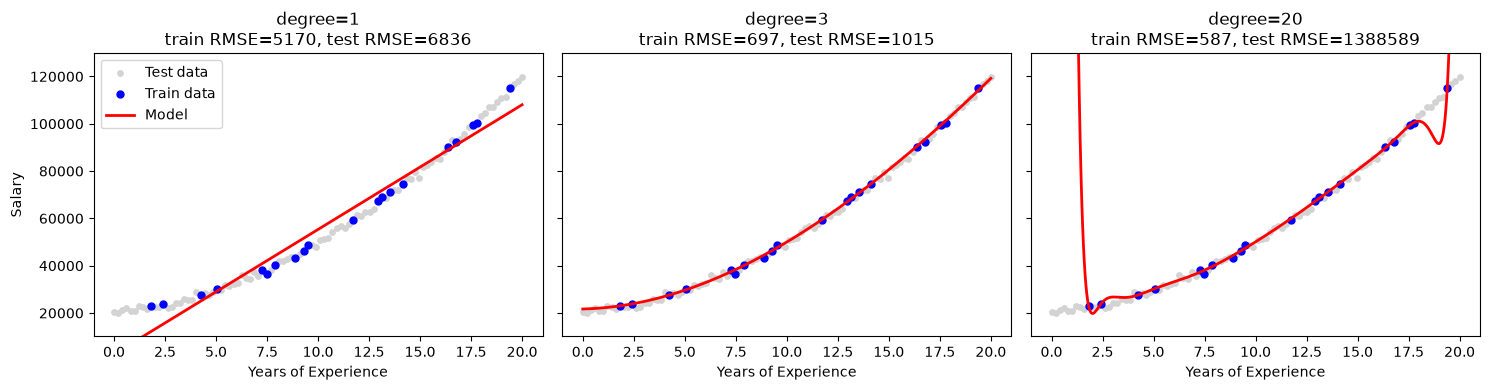

In [22]:
X_tr_1d, X_te_1d, y_tr_1d, y_te_1d = train_test_split(
    X_1d, salary_1d, train_size=20, random_state=0
)
X_plot = np.linspace(0, 20, 500).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, deg in zip(axes, [1, 3, 20]):
    model_deg = Pipeline(steps=[
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=deg)),
        ('regressor', LinearRegression())
    ])
    model_deg.fit(X_tr_1d, y_tr_1d)

    rmse_tr = root_mean_squared_error(y_tr_1d, model_deg.predict(X_tr_1d))
    rmse_te = root_mean_squared_error(y_te_1d, model_deg.predict(X_te_1d))
    print(f"degree={deg:>2}:  RMSE train = {rmse_tr:>10.0f}   RMSE test = {rmse_te:>12.0f}")

    ax.scatter(X_te_1d, y_te_1d, color='lightgray', s=15, label='Test data')
    ax.scatter(X_tr_1d, y_tr_1d, color='blue', s=25, label='Train data')
    ax.plot(X_plot, model_deg.predict(X_plot), color='red', linewidth=2, label='Model')
    ax.set_title(f'degree={deg}\ntrain RMSE={rmse_tr:.0f}, test RMSE={rmse_te:.0f}')
    ax.set_xlabel('Years of Experience')

axes[0].set_ylabel('Salary')
axes[0].set_ylim(salary_1d.min() - 10000, salary_1d.max() + 10000)
axes[0].legend()
plt.tight_layout()
plt.show()

**Samostatný úkol pro pokročilé:**
V Úkolu 4 jsme aplikovali `PolynomialFeatures` na celou šířku matice, tedy i na binární (0/1) sloupce, které vygeneroval One-Hot Encoding. Umocňovat 0 nebo 1 na druhou ale nedává matematický smysl a neúměrně zvětšuje datovou sadu.
*Úkol:* Upravte svůj kód tak, abyste krok `PolynomialFeatures` přesunuli z hlavní modelové Pipeline přímo dovnitř `num_transformer` větve. Tím se polynomiálně umocní pouze čísla a až poté se spojí s kategoriemi.

In [23]:
# BONUS: PolynomialFeatures jen ve větvi pro čísla
num_transformer_poly = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False))   
])

preprocessor_poly = ColumnTransformer(transformers=[
    ('num', num_transformer_poly, num_features),
    ('cat', cat_transformer, cat_features)     
])

model_poly = Pipeline(steps=[
    ('preprocessor', preprocessor_poly),
    ('regressor', LinearRegression())     
])

model_poly.fit(X_train, y_train)
rmse_poly = root_mean_squared_error(y_test, model_poly.predict(X_test))

n_cols_v1 = model[:-1].transform(X_test).shape[1]         # Úkol 4: preprocessor + poly
n_cols_v2 = model_poly[:-1].transform(X_test).shape[1]    # Bonus: jen preprocessor
print(f"Úkol 4 (poly na všem):    {n_cols_v1} sloupců, RMSE test = {rmse:.0f}")
print(f"Bonus  (poly jen čísla):  {n_cols_v2} sloupců, RMSE test = {rmse_poly:.0f}")
print("\nSloupce po předzpracování (bonus):")
print(list(model_poly[:-1].get_feature_names_out()))

Úkol 4 (poly na všem):    55 sloupců, RMSE test = 10056
Bonus  (poly jen čísla):  15 sloupců, RMSE test = 10508

Sloupce po předzpracování (bonus):
['num__YearsExperience', 'num__Age', 'num__Bonus', 'num__YearsExperience^2', 'num__YearsExperience Age', 'num__YearsExperience Bonus', 'num__Age^2', 'num__Age Bonus', 'num__Bonus^2', 'cat__Education_Bachelor', 'cat__Education_Master', 'cat__Education_PhD', 'cat__Department_HR', 'cat__Department_IT', 'cat__Department_Sales']


## 7. Kontrolní otázky (závěrečná sebereflexe)
1. Proč voláme na testovací sadě při generování predikcí pouze metodu `.transform()` (potažmo `.predict()`) a nikdy `.fit_transform()`?

   **Odpověď:** `fit` znamená „nauč se parametry z dat“. Testovací sada simuluje budoucí, nikdy neviděná data. V praxi u nového záznamu také nemáme celou populaci, ze které bychom se mohli znovu učit. Kdybychom na testu zavolali `fit_transform`, (a) informace z testu by unikly do modelu (data leakage) a hodnocení by bylo falešně optimistické, (b) test by byl transformován jinými parametry než trénink, takže by model dostal data v jiném „měřítku“, než na jakém se učil. Proto se vše učí jen z `X_train` a na `X_test` se naučené parametry pouze aplikují. `Pipeline` tohle hlídá automaticky – `model.predict(X_test)` volá uvnitř jen `transform` a `predict`.

2. Pokud proměnná `Education` obsahuje 3 unikátní hodnoty a `Department` také 3 unikátní hodnoty, kolik nových sloupců encodér do naší matice celkově přidá?

   **Odpověď:** 3 + 3 = **6 sloupců** (`Education_Bachelor`, `Education_Master`, `Education_PhD`, `Department_HR`, `Department_IT`, `Department_Sales`)

3. Šum generovaný v naší tabulce v kroku B měl směrodatnou odchylku 2000. Pokud vaše výsledné RMSE vyšlo poblíž této hodnoty, proč můžeme prohlásit náš model za excelentní?

   **Odpověď:** Šum je čistě náhodná složka, která nezávisí na žádném příznaku – žádný model ji nemůže předpovědět (tzv. neredukovatelná chyba). I model, který by znal přesný vzorec, podle kterého byla data vygenerována, by měl RMSE ≈ 2000. RMSE blízko 2000 tedy znamená, že model zachytil veškerou systematickou závislost a zbývající chyba je jen šum ... lépe to prostě už nepůjde

   *Naše výsledky:* Na datech bez chybějících hodnot dosáhl model z Úkolu 4 RMSE ≈ 2029, tedy prakticky hranice šumu. Na datech s 10 % NaN v každém příznaku vyšlo RMSE ≈ 10 056 – nikoli kvůli špatnému modelu, ale protože imputace nedokáže vrátit ztracenou informaci (např. u chybějící `YearsExperience` je doplněn medián 9,9 roku, i když skutečná praxe mohla být 0 nebo 20 let; samotné tyto řádky mají RMSE ≈ 27 000). Kompletní testovací řádky mají RMSE ≈ 2 800.

---
### 7.1 Krátká reflexe na cvičení - díky za pomoc!

Který úkol nebo koncept pro vás byl dnes nejjednodušší? ** Krok A a krok B**

Po zodpovězení všech otázek v návaznosti na kód, vnímate že chápete jak funguje Simple Reflex Agent, k čemu se hodí a jakéí jsou jeho omezení v porovnání k Model-Based Agent? ** Spíše ano, ale je tam hodně neznámích a asi by mě nedocekvalo hnedka, že musím použít toto**
